# 05 — Kok Zhailau at project scale, and what open data can and cannot settle

**Kok Zhailau ski terrain analytics — an independent open-data case study**
Dias Irishev · Geo & Weather Data Scientist, Almaty

Notebooks 01–03 work on a 69 km² rectangle around the plateau; notebook 04
widens to the 404 km² cluster. This one goes the other way: **down to the scale
the project is actually being built at**, and then spends the rest of its length
trying to break its own results.

It is written for three questions an engineering or GIS team on this project
would ask of an outside analyst:

1. **Can you work at our scale?** The operator states a territory of 1,022 ha.
   That is 1/40 of the cluster and 1/7 of the rectangle in notebook 01.
2. **Will your model survive contact with a different input?** The whole chain —
   slope, aspect, horizon, sky view factor, insolation, sunshine duration — is
   re-run on two independent DEMs and the *products* are compared, not the
   elevations.
3. **What do you still need from the ground?** Clear-sky geometry and a
   satellite snow-detection frequency are not a snowpack model. The last
   section says exactly which quantities cannot be settled from orbit.

### What the operator publishes, and what it does not

From the 18 November 2026 board meeting of Kazakh Tourism Development, chaired
by the Prime Minister, and the company's own release: **60 km of runs, 17 lifts
of which 11 cableways are POMA's, about 70 % of the runs green and blue, up to
10 000 skiers a day, 1 022 ha of territory with about 20 ha built on, launch in
December 2028**, a mountain-village concept by BIG and timber base- and
top-station structures by Blumer-Lehmann, with Ecosign also engaged.

What is **not** published: any boundary, any station coordinate, any lift
alignment, any run, any elevation, and any capacity in persons per hour. So
**no footprint in this notebook is the project's own**, and no planned lift is
drawn anywhere in this release. The 1,022 ha is reconstructed two ways and every
number is reported against both, which is the only honest way to use a figure
whose shape is unknown.

In [1]:
import os
os.environ["KZ_AREA"] = "kz_project"       # must be set before importing config

import json
import sys
from datetime import date
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import footprint
import ski_terrain as ST
from config import (AOI_BBOX_WGS84, AREA_LABEL, AREA_NOTE, HORIZON_N_AZIMUTH,
                    INTERIM, OUT_PNG, OUT_TAB, OUT_TIF, OUTLOOK_YEAR,
                    PLATEAU_POINT, PROJECT_AREA_HA, PROJECT_BUILT_HA,
                    PROJECT_CABLEWAYS_POMA, PROJECT_GREEN_BLUE_SHARE,
                    PROJECT_LAUNCH, PROJECT_LIFTS, PROJECT_PISTE_KM,
                    PROJECT_SKIERS_PER_DAY, SKIABLE_SLOPE_MAX, SKIABLE_SLOPE_MIN,
                    STUDY_AREAS, SUN_HOUR_STEP_MIN)
from dem import write_geotiff
from grids import DEM_GRID, S2_GRID
from pipeline_terrain import all_insolation, terrain
from viz import ELEV_CMAP, map_panel, save

pd.set_option("display.width", 185)
RUN_DATE = date.today().isoformat()
print(f"run date        : {RUN_DATE}")
print(f"area            : {AREA_LABEL}")
print(f"bbox            : {AOI_BBOX_WGS84}")
print(f"30 m grid       : {DEM_GRID.shape}  {DEM_GRID.area_km2:.2f} km²")
print(f"20 m snow grid  : {S2_GRID.shape}  {S2_GRID.area_km2:.2f} km²")
print(f"horizon         : {HORIZON_N_AZIMUTH} azimuths ({360/HORIZON_N_AZIMUTH:.0f}° spacing)")
print(f"sunshine step   : {SUN_HOUR_STEP_MIN} min")
print(f"\n{AREA_NOTE}")

run date        : 2026-11-19
area            : Kok Zhailau project-scale window
bbox            : (76.965, 43.115, 77.045, 43.17)
30 m grid       : (210, 223)  42.15 km²
20 m snow grid  : (315, 333)  41.96 km²
horizon         : 72 azimuths (5° spacing)
sunshine step   : 5 min

Project-scale window centred on the plateau reference point. Kazakh Tourism Development states a project territory of 1,022 ha with about 20 ha built up; no boundary has been published. The 1,022 ha footprints are therefore derived inside this window (see footprint.py) and this window is the surrounding context, not the project area.


In [2]:
published = pd.DataFrame([
    {"parameter": "piste length", "published": f"{PROJECT_PISTE_KM:.0f} km"},
    {"parameter": "lifts", "published": f"{PROJECT_LIFTS} "
     f"({PROJECT_CABLEWAYS_POMA} cableways by POMA; the other 6 are not described)"},
    {"parameter": "share of runs green and blue",
     "published": f"about {PROJECT_GREEN_BLUE_SHARE*100:.0f} %"},
    {"parameter": "designed daily capacity",
     "published": f"up to {PROJECT_SKIERS_PER_DAY:,} skiers/day"},
    {"parameter": "project territory", "published": f"{PROJECT_AREA_HA:,.0f} ha"},
    {"parameter": "built-up area", "published": f"about {PROJECT_BUILT_HA:.0f} ha "
     f"({100*PROJECT_BUILT_HA/PROJECT_AREA_HA:.1f} % of the territory)"},
    {"parameter": "launch", "published": PROJECT_LAUNCH.replace("-", "/")},
    {"parameter": "boundary / lift alignments / station coordinates",
     "published": "not published"},
    {"parameter": "lift capacity (persons per hour)", "published": "not published"},
    {"parameter": "piste length by difficulty", "published": "not published"},
])
published.to_csv(OUT_TAB / "published_project_parameters.csv", index=False)
print(published.to_string(index=False))

                                       parameter                                                published
                                    piste length                                                    60 km
                                           lifts 17 (11 cableways by POMA; the other 6 are not described)
                    share of runs green and blue                                               about 70 %
                         designed daily capacity                                  up to 10,000 skiers/day
                               project territory                                                 1,022 ha
                                   built-up area                     about 20 ha (2.0 % of the territory)
                                          launch                                                  2028/12
boundary / lift alignments / station coordinates                                            not published
                lift capacity (persons per hou

## 1. Reconstructing 1,022 ha two ways

`footprint.py` derives two footprints of exactly the stated area inside the
window, both centred on the plateau reference point used since notebook 01:

* **A — disc.** The 1,022 ha closest to that point. It uses no terrain
  information at all, so it cannot flatter the ground.
* **B — gentlest.** The 1,022 ha of gentlest ground within 3 km of the same
  point, slope mean-filtered over 150 m first so a single flat pixel inside a
  cliff band cannot outrank a real bench. This is the most favourable territory
  a planner could pick, so any gradient conclusion that survives here is not an
  artefact of where the line was drawn.

The contiguity columns are the point of the table.

In [3]:
t = terrain()
fps = footprint.build(DEM_GRID, t["slope"])
fp_summary = footprint.summary(fps, DEM_GRID, t["dem"], t["slope"])
fp_summary.to_csv(OUT_TAB / "footprint_summary.csv", index=False)
print(fp_summary.to_string(index=False))

NAME_A = [k for k in fps if k.startswith("footprint A")][0]
NAME_B = [k for k in fps if k.startswith("footprint B")][0]
NAME_W = [k for k in fps if k.startswith("project window")][0]
A, B, W = fps[NAME_A], fps[NAME_B], fps[NAME_W]

nA, bigA, _ = footprint.components(A)
nB, bigB, bigB_mask = footprint.components(B)
ha = DEM_GRID.res ** 2 / 1e4
print(f"\nfootprint A: {nA} piece(s), largest {bigA*ha:,.0f} ha")
print(f"footprint B: {nB} pieces,    largest {bigB*ha:,.0f} ha "
      f"({100*bigB/B.sum():.0f} % of the footprint)")
print("\nThe gentle ground exists. It is not in one place.")

                            footprint  area_ha  pieces  largest_piece_ha  largest_piece_share  elev_min_m  elev_median_m  elev_max_m  vertical_m  slope_median_deg  slope_p90_deg
              project window (42 km2)   4214.7       1            4214.7                1.000      1341.0         2015.0      3208.0      1867.0              28.3           37.0
footprint A: 1022 ha disc (r=1.80 km)   1022.0       1            1022.0                1.000      1653.0         2146.0      2843.0      1190.0              28.8           36.9
        footprint B: gentlest 1022 ha   1022.0      67             454.9                0.445      1424.0         1963.0      3157.0      1733.0              20.0           27.6

footprint A: 1 piece(s), largest 1,022 ha
footprint B: 67 pieces,    largest 455 ha (45 % of the footprint)

The gentle ground exists. It is not in one place.


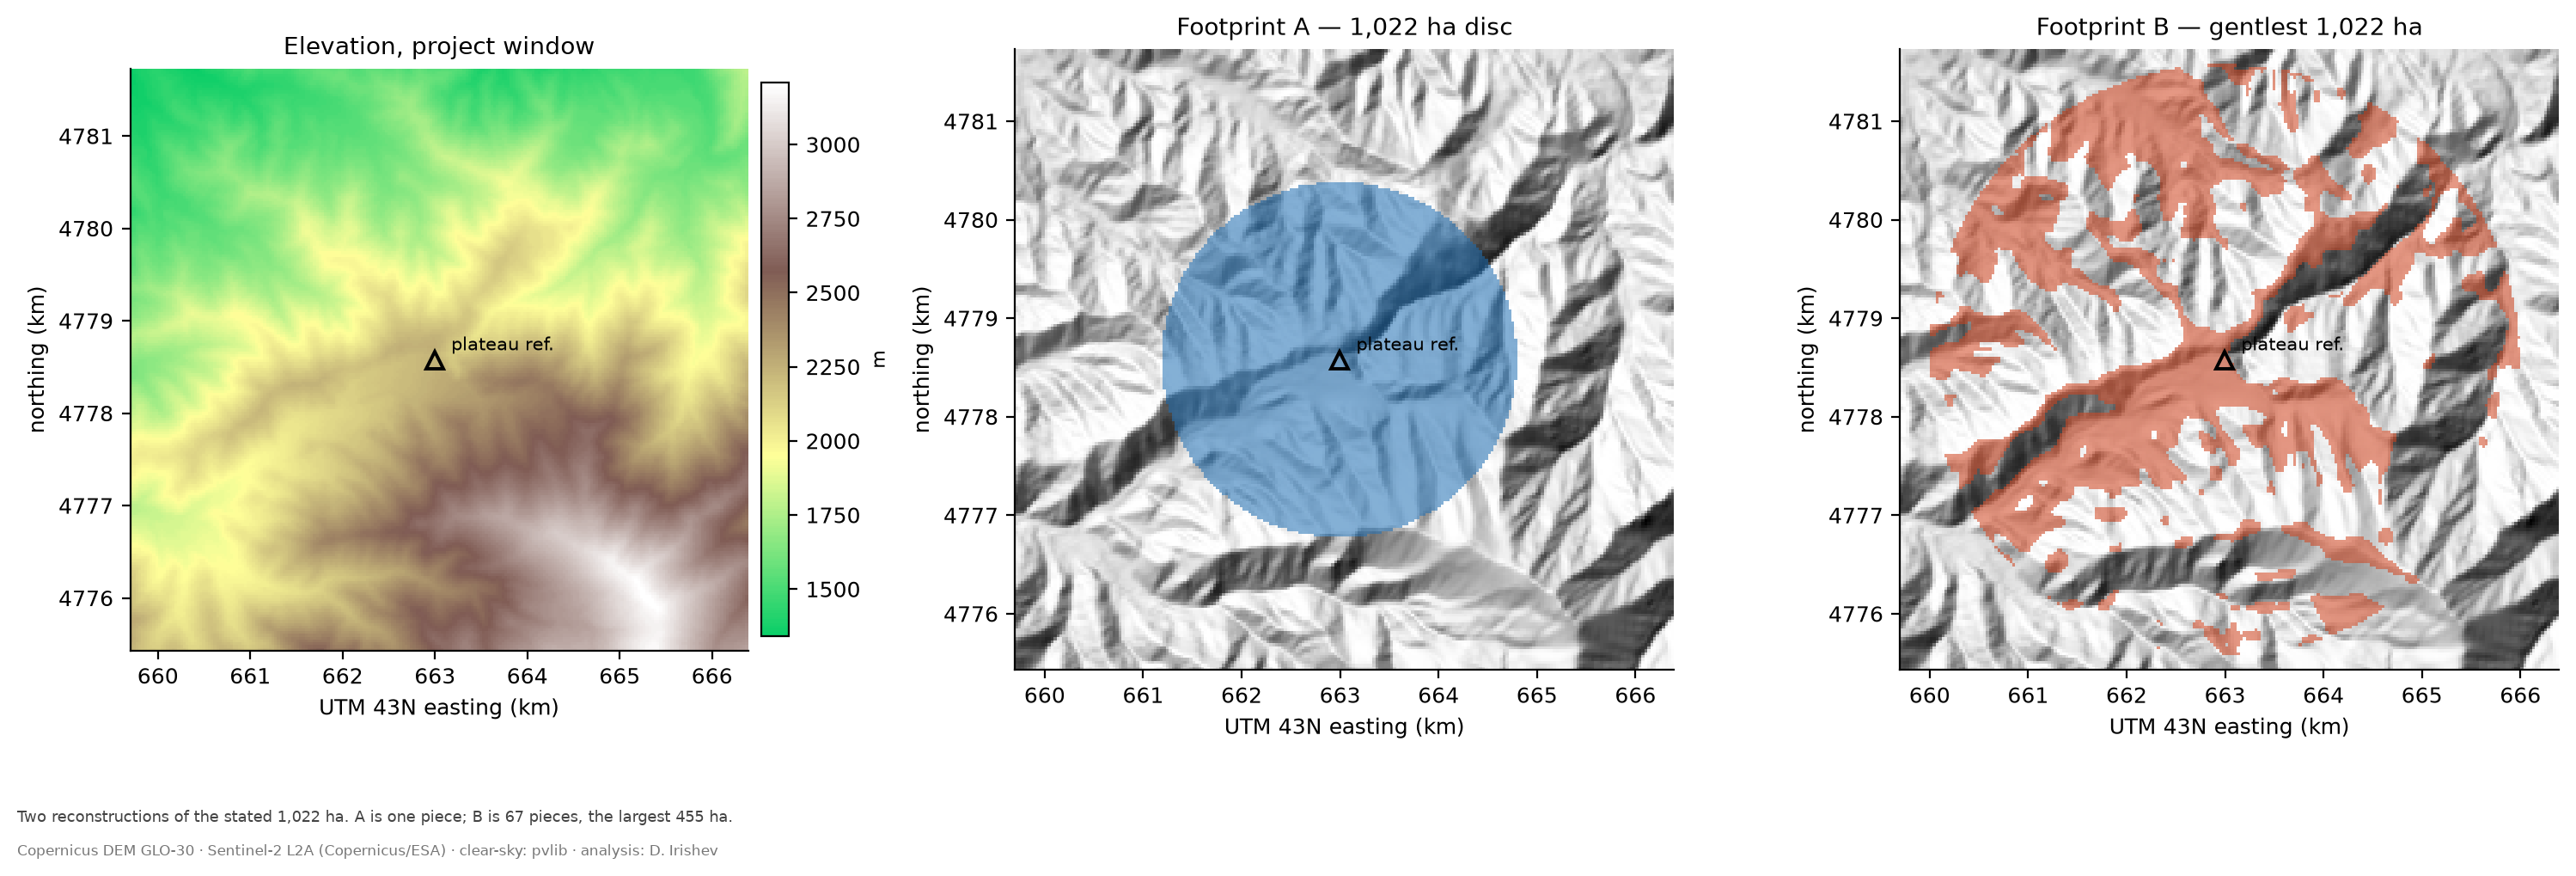

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/kz_project/png/05_footprints.png')

In [4]:
from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(1, 3, figsize=(15.0, 5.0))
map_panel(axes[0], t["dem"], DEM_GRID, cmap=ELEV_CMAP,
          title="Elevation, project window", cbar_label="m")
for ax, mask, colour, ttl in [
        (axes[1], A, "#1f6fb4", f"Footprint A — {PROJECT_AREA_HA:,.0f} ha disc"),
        (axes[2], B, "#d1441f", f"Footprint B — gentlest {PROJECT_AREA_HA:,.0f} ha")]:
    layer = np.where(mask, 1.0, np.nan)
    map_panel(ax, layer, DEM_GRID, cmap=ListedColormap([colour]), vmin=0, vmax=1,
              dem=t["dem"], shade=0.45, title=ttl, cbar=False)
fig.tight_layout()
save(fig, "05_footprints.png",
     f"Two reconstructions of the stated {PROJECT_AREA_HA:,.0f} ha. "
     f"A is one piece; B is {nB} pieces, the largest {bigB*ha:,.0f} ha.")

## 2. The published mix of runs against the ground

Gradient classes are the percent grades of the **British Columbia All Season
Resort Guidelines, Chapter II (Mountain Resorts)**, converted to degrees. That
is a planning convention from another jurisdiction, chosen because it is public
and because it is the practice the named planners work in — it is **not** a
Kazakh standard and not this project's design criteria. "Green and blue" in the
operator's wording is read as beginner through low intermediate, i.e. grades up
to 35 % (19.3°).

In [5]:
grad = ST.class_table(t["slope"], DEM_GRID, fps)
grad.to_csv(OUT_TAB / "gradient_classes_by_footprint.csv", index=False)
piv = grad.pivot_table(index=["gradient_class", "slope_from_deg"],
                       columns="area", values="share").sort_index(level=1)
piv.index = [i[0] for i in piv.index]
print((100 * piv).round(1).to_string())

gb = ST.green_blue_share(t["slope"], fps, DEM_GRID)
gb.to_csv(OUT_TAB / "green_blue_availability.csv", index=False)
print()
print(gb.to_string(index=False))

area                   footprint A: 1022 ha disc (r=1.80 km)  footprint B: gentlest 1022 ha  project window (42 km2)
Beginner                                                 3.6                            7.3                      3.2
Novice                                                   7.9                           17.2                      7.7
Low intermediate                                         8.8                           22.2                     10.5
Intermediate                                             6.0                           13.4                      6.6
Advanced intermediate                                   34.5                           37.9                     33.3
Expert                                                  39.1                            2.1                     38.7

                                 area  area_ha  green_blue_ha  green_blue_share  slope_median_deg  above_31deg_share
              project window (42 km2)   4214.7          901.6  

The operator publishes a **length** (60 km) and a **mix** (about 70 % green and
blue) but no **width**, and width is what turns a length into an area. Three
plausible mean widths are carried through instead of one assumed value.

In [6]:
demand = ST.piste_area_demand(PROJECT_PISTE_KM, PROJECT_GREEN_BLUE_SHARE)
feas = pd.concat([ST.feasibility(demand, r.green_blue_ha, r.area)
                  for _, r in gb.iterrows()], ignore_index=True)
feas.to_csv(OUT_TAB / "green_blue_feasibility.csv", index=False)
print(feas[["footprint", "assumed_mean_piste_width_m", "green_blue_piste_ha",
            "available_green_blue_ha", "share_of_available_consumed"]]
      .to_string(index=False))

row_a = feas[(feas.footprint == NAME_A) & (feas.assumed_mean_piste_width_m == 40)].iloc[0]
row_b = feas[(feas.footprint == NAME_B) & (feas.assumed_mean_piste_width_m == 40)].iloc[0]
print(f"""
Read-out at a 40 m mean width:
  on footprint A the green/blue runs would need {row_a.green_blue_piste_ha:.0f} ha of the
  {row_a.available_green_blue_ha:.0f} ha of gentle ground that exists there —
  {100*row_a.share_of_available_consumed:.0f} % of it, and at 50 m the arithmetic does not close at all;
  on footprint B, the most favourable 1,022 ha, the same runs need
  {100*row_b.share_of_available_consumed:.0f} % — but that gentle ground arrives in {nB} pieces.

So the binding constraint on a beginner-led resort here is not how much gentle
ground Kok Zhailau has. It is how little of it is connected.""")

                            footprint  assumed_mean_piste_width_m  green_blue_piste_ha  available_green_blue_ha  share_of_available_consumed
              project window (42 km2)                        30.0                126.0                    901.6                        0.140
              project window (42 km2)                        40.0                168.0                    901.6                        0.186
              project window (42 km2)                        50.0                210.0                    901.6                        0.233
footprint A: 1022 ha disc (r=1.80 km)                        30.0                126.0                    208.1                        0.605
footprint A: 1022 ha disc (r=1.80 km)                        40.0                168.0                    208.1                        0.807
footprint A: 1022 ha disc (r=1.80 km)                        50.0                210.0                    208.1                        1.009
        footp

In [7]:
cls = ST.class_index(t["slope"]).astype("float32")
cls[~np.isfinite(t["slope"])] = np.nan
write_geotiff(OUT_TIF / "gradient_class.tif", cls, DEM_GRID, nodata=-1,
              description="BC All Season Resort Guidelines gradient class, 0=beginner..5=expert")
for nm, m, fn in [("footprint_a_disc", A, "footprint_a_disc.tif"),
                  ("footprint_b_gentlest", B, "footprint_b_gentlest.tif")]:
    write_geotiff(OUT_TIF / fn, m.astype("uint8"), DEM_GRID, nodata=255,
                  dtype="uint8", description=f"derived {PROJECT_AREA_HA:.0f} ha footprint: {nm}")
for nm in ("dem", "slope", "aspect", "svf"):
    arr = t[nm]
    write_geotiff(OUT_TIF / f"{'elevation_m' if nm=='dem' else nm}.tif",
                  arr, DEM_GRID, nodata=-9999,
                  description=f"{nm} on the project-scale grid")
print("rasters written:", sorted(p.name for p in OUT_TIF.glob("*.tif")))

rasters written: ['aspect.tif', 'elevation_m.tif', 'footprint_a_disc.tif', 'footprint_b_gentlest.tif', 'gradient_class.tif', 'insolation_nov_apr_2027_kwh_m2.tif', 'slope.tif', 'snow_frequency_4season.tif', 'snow_frequency_spring_window_4season.tif', 'sun_hours_nov_apr_2027.tif', 'svf.tif']


## 3. Sun at project scale: energy and duration, per footprint

At 42 km² the horizon can be sampled every 5° instead of every 10°, and the
sunshine-duration integration stepped every 5 minutes instead of 15. Both are
refinements the cluster run could not afford; the cost of the finer sampling is
reported below so the reader can see what it bought.

In [8]:
from pipeline_sun import run as run_sun

sun, sun_monthly, sun_profile, zone_masks, _ = run_sun(OUTLOOK_YEAR)
cols = ["month_name", "days", "median_sun_hours", "max_sun_hours",
        "median_hours_per_day"] + [c for c in sun_monthly.columns
                                   if c.startswith("median_h__footprint")]
print(sun_monthly[cols].to_string(index=False))

season_hours = sum(sun[m]["hours"] for m in sun)
ins = all_insolation(t)
season_kwh = (ins[f"{OUTLOOK_YEAR}_11"]["total"] + ins[f"{OUTLOOK_YEAR}_12"]["total"]
              + ins[f"{OUTLOOK_YEAR}_01"]["total"] + ins[f"{OUTLOOK_YEAR}_02"]["total"]
              + ins[f"{OUTLOOK_YEAR}_03"]["total"] + ins[f"{OUTLOOK_YEAR}_04"]["total"])
write_geotiff(OUT_TIF / f"sun_hours_nov_apr_{OUTLOOK_YEAR}.tif", season_hours,
              DEM_GRID, nodata=-9999, description="direct sunshine hours, Nov-Apr")
write_geotiff(OUT_TIF / f"insolation_nov_apr_{OUTLOOK_YEAR}_kwh_m2.tif", season_kwh,
              DEM_GRID, nodata=-9999, description="clear-sky plane-of-array energy, Nov-Apr")

rows = []
for nm, m in fps.items():
    rows.append({"footprint": nm,
                 "sun_hours_median": round(float(np.nanmedian(season_hours[m])), 1),
                 "sun_hours_p10": round(float(np.nanpercentile(season_hours[m], 10)), 1),
                 "sun_hours_p90": round(float(np.nanpercentile(season_hours[m], 90)), 1),
                 "insolation_median": round(float(np.nanmedian(season_kwh[m])), 1),
                 "december_hours_median": round(float(np.nanmedian(sun[12]["hours"][m])), 1),
                 "december_hours_per_day": round(float(np.nanmedian(sun[12]["hours"][m]))/31, 2),
                 "march_hours_median": round(float(np.nanmedian(sun[3]["hours"][m])), 1)})
sun_fp = pd.DataFrame(rows)
sun_fp.to_csv(OUT_TAB / "sun_by_footprint.csv", index=False)
print()
print(sun_fp.to_string(index=False))

dA = sun_fp.loc[sun_fp.footprint == NAME_A, "december_hours_median"].iloc[0]
dB = sun_fp.loc[sun_fp.footprint == NAME_B, "december_hours_median"].iloc[0]
print(f"""
December, the month a December launch has to work in: footprint A gets a median
of {dA:.0f} h of direct sun across the whole month — {dA/31:.1f} h a day — against {dB:.0f} h
({dB/31:.1f} h a day) on footprint B. Where the 1,022 ha is put inside Kok Zhailau
changes mid-winter sun by a factor of {dB/dA:.1f}. The plateau itself faces the city,
which is north: good for holding snow, poor for winter sun.""")

month_name  days  median_sun_hours  max_sun_hours  median_hours_per_day  median_h__footprint A: 1022 ha disc (r=1.80 km)  median_h__footprint B: gentlest 1022 ha
  November    30             133.4          276.3                  4.45                                            117.5                                    179.0
  December    31              75.2          264.9                  2.43                                             34.8                                    135.0
   January    31             109.0          275.2                  3.52                                             84.1                                    161.6
  February    28             172.6          282.7                  6.16                                            168.1                                    208.4
     March    31             267.9          364.1                  8.64                                            269.3                                    293.3
     April    30            

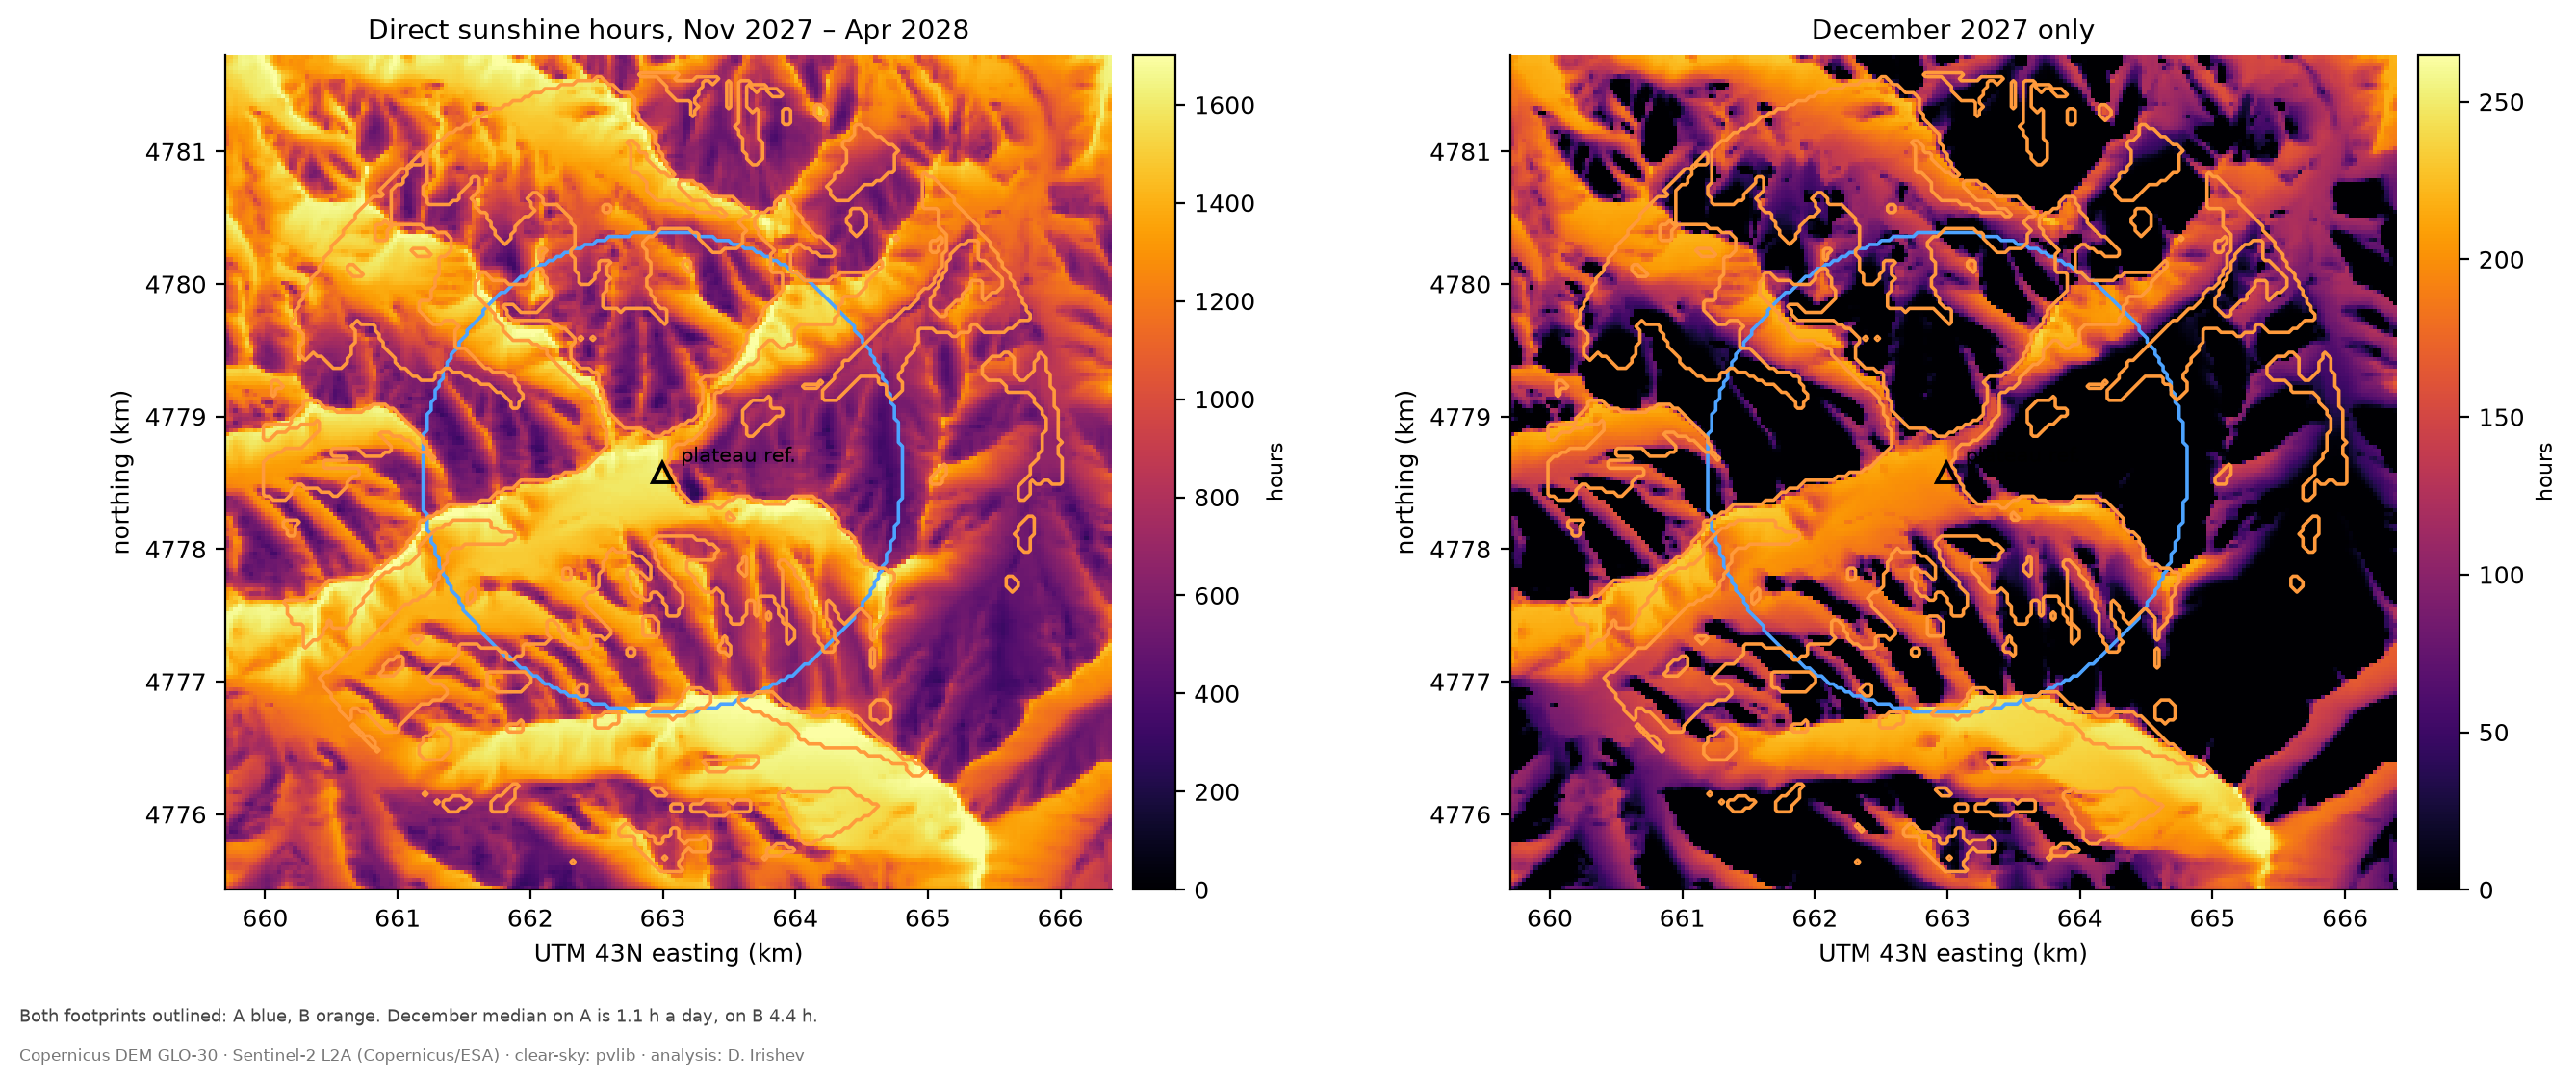

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/kz_project/png/05_sun_hours_project_scale.png')

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.2))
vmax = float(np.nanpercentile(season_hours, 99.5))
map_panel(axes[0], season_hours, DEM_GRID, cmap="inferno", vmin=0, vmax=vmax,
          title=f"Direct sunshine hours, Nov {OUTLOOK_YEAR} – Apr {OUTLOOK_YEAR+1}",
          cbar_label="hours")
map_panel(axes[1], sun[12]["hours"], DEM_GRID, cmap="inferno", vmin=0,
          title=f"December {OUTLOOK_YEAR} only", cbar_label="hours")
# map_panel draws in kilometres, so every overlay must be in kilometres too.
EXT_KM = [DEM_GRID.xmin / 1000, DEM_GRID.xmax / 1000,
          DEM_GRID.ymin / 1000, DEM_GRID.ymax / 1000]
for ax in axes:
    for m, col in [(A, "#4da3ff"), (B, "#ff9a3c")]:
        ax.contour(np.flipud(m.astype(float)), levels=[0.5], colors=[col],
                   linewidths=1.3, extent=EXT_KM)
fig.tight_layout()
save(fig, "05_sun_hours_project_scale.png",
     f"Both footprints outlined: A blue, B orange. December median on A is "
     f"{dA/31:.1f} h a day, on B {dB/31:.1f} h.")

## 4. Snow at project scale, from the scenes already read

The 20 m project grid is a pixel-aligned subset of the 20 m cluster grid, so
the 115 Sentinel-2 windows read for notebook 04 contain every observation this
window needs. `reuse_cache.py` asserts the alignment and slices the arrays; no
pixel is resampled and nothing is downloaded again. The cell below proves that
by re-reading one scene from the COGs and comparing bit for bit.

In [10]:
import reuse_cache as RC
import s2
from grids import grid_from_raster

cluster_s2 = grid_from_raster(Path.cwd().parent / "outputs" / "cluster" /
                              "geotiff" / "cluster_snow_frequency_month_03.tif")
RC.copy_stac_records(Path.cwd().parent / "data" / "interim" / "cluster")
slice_info = RC.slice_scene_cache(cluster_s2, S2_GRID)

recs = json.load(open(INTERIM / "stac_records.json"))
flat = [r for v in recs.values() for r in v]
probe = sorted(flat, key=lambda r: r["scene_id"])[len(flat) // 2]
cached = s2.fetch_scene(probe, S2_GRID)
fresh = s2.fetch_scene(probe, S2_GRID, force=True)
check = {k: int((cached[k].astype(bool) != fresh[k].astype(bool)).sum())
         for k in ("snow", "valid")}
print(f"\nre-read check on {probe['scene_id']}: "
      f"{check['snow']} snow and {check['valid']} validity pixels differ "
      f"out of {cached['snow'].size:,} — identical: {check == {'snow': 0, 'valid': 0}}")
pd.DataFrame([{**slice_info, "probe_scene": probe["scene_id"],
               "snow_pixels_differing": check["snow"],
               "valid_pixels_differing": check["valid"],
               "pixels_compared": int(cached["snow"].size)}]).to_csv(
    OUT_TAB / "scene_cache_reuse_check.csv", index=False)

STAC records: 115 scenes (reused from cluster)
scene cache 658320_4770420_1040x970_20m -> 659720_4775440_333x315_20m: 0 written, 115 already present (offset row 404, col 70; window 315x333)



re-read check on S2B_43TFH_20231126_0_L2A: 0 snow and 0 validity pixels differ out of 104,895 — identical: True


In [11]:
import resample
from pipeline_snow import coverage_table, current_season_days, historical_days, load_days
from snow import coverage_bias, select_days, snow_frequency
from config import SPRING_WINDOW

days, manifest, failed = load_days(verbose=False)
hist = historical_days(days)
print(f"dates: {len(days)} total, {len(hist)} inside the four completed seasons, "
      f"{len(failed)} failures")
manifest.to_csv(OUT_TAB / "scene_manifest.csv", index=False)

spring = select_days(hist, month_day_window=SPRING_WINDOW)
freq_spring = snow_frequency(spring)
freq_all = snow_frequency(hist)
print(coverage_table({"four seasons, all dates": hist,
                      "spring window, four seasons": spring}).to_string(index=False))

write_geotiff(OUT_TIF / "snow_frequency_4season.tif", freq_all["frequency"],
              S2_GRID, nodata=-9999,
              description="snow detection frequency, 4 seasons, equal season weight")
write_geotiff(OUT_TIF / "snow_frequency_spring_window_4season.tif",
              freq_spring["frequency"], S2_GRID, nodata=-9999,
              description=f"snow detection frequency, {SPRING_WINDOW[0]}..{SPRING_WINDOW[1]}, 4 seasons")

dates: 112 total, 111 inside the four completed seasons, 0 failures
                     period  n_dates  n_seasons  median_valid_obs_per_pixel  coverage_min4 first_date  last_date
    four seasons, all dates      111          4                          54         0.9969 2022-11-01 2026-04-29
spring window, four seasons       31          4                          24         0.9821 2023-03-11 2026-04-14


PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/kz_project/geotiff/snow_frequency_spring_window_4season.tif')

### The bias this release used to leave implicit

A pixel only enters a monthly snow map once it has four cloud- and shadow-free
observations. Steep shaded ground fails that test more often, so the pixels
that qualify can be sunnier and gentler than the terrain as a whole — and in
December, when valid observations are scarcest, that skew falls straight on the
quantity being measured. `snow.coverage_bias` now measures it.

In [12]:
ins20 = resample.to_grid(season_kwh, src=DEM_GRID, dst=S2_GRID)
slope20 = resample.to_grid(t["slope"], src=DEM_GRID, dst=S2_GRID)
bias = coverage_bias(hist, {"insolation": ins20, "slope": slope20})
bias.to_csv(OUT_TAB / "snow_coverage_bias.csv", index=False)
print(bias[["month", "n_dates", "qualifying_share", "median_valid_obs",
            "insolation__qualifying", "insolation__whole_area", "insolation__skew",
            "slope__qualifying", "slope__whole_area", "slope__skew"]].to_string(index=False))
worst = bias.loc[bias.qualifying_share.idxmin()]
print(f"""
Thinnest month: {int(worst.month):02d}, {100*worst.qualifying_share:.0f} % of the window qualifies, and the
pixels that do sit {worst['insolation__skew']:+.0f} kWh/m² and {worst['slope__skew']:+.1f}° away from the area as a
whole. Any monthly snow figure for that month is a statement about the sunnier,
gentler part of the terrain, not about the terrain. Reported, not hidden.""")

 month  n_dates  qualifying_share  median_valid_obs  insolation__qualifying  insolation__whole_area  insolation__skew  slope__qualifying  slope__whole_area  slope__skew
    11       24            0.7088                11                  643.21                  515.48            127.73              25.14              28.14        -3.01
    12       16            0.4320                 1                  800.79                  515.48            285.31              23.64              28.14        -4.50
     1       16            0.5279                 5                  746.69                  515.48            231.21              23.93              28.14        -4.21
     2       13            0.8269                 8                  573.71                  515.48             58.23              26.99              28.14        -1.15
     3       25            0.9794                21                  523.82                  515.48              8.34              27.90              28.14

## 5. Kok Zhailau against Shymbulak and Oi-Qaragai — one rule for all three

The previous release compared Kok Zhailau against the OSM
`landuse=winter_sports` polygons for Shymbulak and Oi-Qaragai. Those are 2.2
and 1.0 km², far smaller than either resort operates, so the comparison was a
10 km² territory against a pair of map labels. `resorts.py` replaces it with
one rule for every place: **the ground within 150 m of its lift lines, unioned
with the ground within 100 m of its pistes.** Lines are assigned to the nearest
named place within 3.5 km; anything further stays unassigned.

Kok Zhailau has neither lifts nor pistes, because nothing is built there, so it
enters as its reconstructed footprints. That asymmetry is real and cannot be
removed — a working resort's corridors are *where planners chose to build*,
which is a selected sample of good terrain. That is exactly why footprint B,
Kok Zhailau's own best ground, is the reference below: best-selected against
best-selected.

In [13]:
import osm
import resorts
from grids import grid_from_raster

# This notebook is pinned to the project window, so config's AOI is the project
# window too. The OSM features for the comparison must therefore be clipped to
# the CLUSTER bbox explicitly, or Shymbulak and Oi-Qaragai fall outside and the
# comparison silently reduces to Kok Zhailau against nothing.
CLUSTER_BBOX = STUDY_AREAS["cluster"]["bbox"]
feat = osm.clip(osm.load(), bbox=CLUSTER_BBOX)

CG = Path.cwd().parent / "outputs" / "cluster" / "geotiff"
cluster_grid = grid_from_raster(CG / "cluster_elevation_m.tif")


def read_cluster(name):
    import rasterio
    with rasterio.open(CG / name) as s:
        a = s.read(1).astype("float32")
        if s.nodata is not None:
            a[a == s.nodata] = np.nan
    return a


c_dem = read_cluster("cluster_elevation_m.tif")
c_slope = read_cluster("cluster_slope_deg.tif")
c_ins = read_cluster(f"insolation_nov_apr_{OUTLOOK_YEAR}_kwh_m2.tif")
c_hrs = read_cluster(f"sun_hours_nov_apr_{OUTLOOK_YEAR}.tif")
c_snow20 = read_cluster("cluster_snow_frequency_month_03.tif")
c_snow = resample.to_grid(c_snow20, src=grid_from_raster(
    CG / "cluster_snow_frequency_month_03.tif"), dst=cluster_grid)

inv = resorts.inventory(feat)
inv.to_csv(OUT_TAB / "resort_inventory.csv", index=False)
print(inv[["place", "lifts", "lift_km", "pistes", "piste_km"]].to_string(index=False))
print("\nnamed lifts per place:")
for _, r in inv.iterrows():
    if r.named_lifts:
        print(f"  {r.place}: {r.named_lifts}")

c_fps = footprint.build(cluster_grid, c_slope)
cA = [v for k, v in c_fps.items() if k.startswith("footprint A")][0]
cB = [v for k, v in c_fps.items() if k.startswith("footprint B")][0]
areas = {"Kok Zhailau — footprint A (disc)": cA,
         "Kok Zhailau — footprint B (gentlest)": cB,
         **resorts.envelopes(cluster_grid, feat)}
ha_c = cluster_grid.res ** 2 / 1e4
rows = []
for k, m in areas.items():
    rows.append({"area": k, "area_ha": round(m.sum() * ha_c, 1),
                 "elev_min_m": round(float(np.nanmin(c_dem[m])), 0),
                 "elev_median_m": round(float(np.nanmedian(c_dem[m])), 0),
                 "elev_max_m": round(float(np.nanmax(c_dem[m])), 0),
                 "slope_median_deg": round(float(np.nanmedian(c_slope[m])), 1),
                 "insolation_median": round(float(np.nanmedian(c_ins[m])), 0),
                 "sun_hours_median": round(float(np.nanmedian(c_hrs[m])), 0),
                 "snow_freq_march_median": round(float(np.nanmedian(c_snow[m])), 3)})
area_tbl = pd.DataFrame(rows)
area_tbl.to_csv(OUT_TAB / "three_area_overview.csv", index=False)
print()
print(area_tbl.to_string(index=False))

     place  lifts  lift_km  pistes  piste_km
 Shymbulak      7    10.73      24      18.6
Oi-Qaragai      8     6.51       6       4.7
unassigned      6     3.81       2       1.1

named lifts per place:
  Shymbulak: Combi-1; Combi-2; KKD-4; Left Talgar; T-Bar-1; T-Bar-2; Медеу - Шымбұлақ аспалы жолы
  Oi-Qaragai: Aqtas Expres; Barys; Jer-sy; Samal; Sanjar; Umai
  unassigned: 4-ый бугельный подъёмник, Elik Sai ski lift ~ 550м; Kok Tebe Cable Car; Pioneer ski area ski lift; Бугельный подъёмник учебной трассы, Elik Sai ski lift; Второй бугельный подъёмник, Elik Sai ski lift ~ 650 м



                                area  area_ha  elev_min_m  elev_median_m  elev_max_m  slope_median_deg  insolation_median  sun_hours_median  snow_freq_march_median
    Kok Zhailau — footprint A (disc)   1022.0      1653.0         2146.0      2844.0              28.8              459.0             984.0                   0.848
Kok Zhailau — footprint B (gentlest)   1022.0      1424.0         1964.0      3157.0              20.0              624.0            1321.0                   0.792
            Shymbulak operating area    377.6      1605.0         2417.0      3282.0              22.4              552.0            1056.0                   0.997
           Oi-Qaragai operating area    264.5      1518.0         1732.0      2279.0              20.4              642.0            1318.0                   0.846


Those medians are not yet a comparison: the areas sit at different altitudes
and different gradients, and both drive sun and snow. So the next table holds
both constant — every area restricted to skiable gradients, then compared band
by 200 m band, and only in bands where an area has at least 50 pixels.

In [14]:
ski_c = np.isfinite(c_slope) & (c_slope >= SKIABLE_SLOPE_MIN) & (c_slope <= SKIABLE_SLOPE_MAX)
areas_ski = {k: v & ski_c for k, v in areas.items()}
layers = {"insolation_kwh_m2": c_ins, "sun_hours": c_hrs, "snow_freq_march": c_snow}
bands = resorts.band_table(areas_ski, c_dem, layers, cluster_grid, step_m=200.0)
bands.to_csv(OUT_TAB / "three_area_elevation_bands.csv", index=False)
print(bands.pivot_table(index="band_m", columns="area",
                        values="insolation_kwh_m2").round(0).to_string())

REF = "Kok Zhailau — footprint B (gentlest)"
matched = pd.concat([resorts.matched_pairs(bands, lay, REF)
                     for lay in layers], ignore_index=True)
matched.to_csv(OUT_TAB / "three_area_matched_differences.csv", index=False)
print()
print(matched[["area", "layer", "shared_bands", "band_low_min_m", "band_low_max_m",
               "median_difference"]].to_string(index=False))

def mdiff(prefix, layer):
    sel = matched[matched.area.str.startswith(prefix) & (matched.layer == layer)]
    if sel.empty:
        raise AssertionError(f"no matched bands for {prefix} / {layer}: "
                             f"areas present = {sorted(matched.area.unique())}")
    return float(sel.median_difference.iloc[0])


shy_i, shy_s = mdiff("Shymbulak", "insolation_kwh_m2"), mdiff("Shymbulak", "snow_freq_march")
oq_i, oq_s = mdiff("Oi-Qaragai", "insolation_kwh_m2"), mdiff("Oi-Qaragai", "snow_freq_march")
print(f"""
Against Kok Zhailau's own best 1,022 ha, at matched elevations and matched
gradients:

  Shymbulak's working corridors receive {shy_i:+.0f} kWh/m² of winter energy and hold
  snow {shy_s:+.3f} more often in March. They trade sun for snow.
  Oi-Qaragai receives {oq_i:+.0f} kWh/m² and holds snow {oq_s:+.3f} more often — but it sits
  at 1,520-2,280 m under forest, where NDSI under canopy is a known weak point,
  so its snow figure is the least comparable number in this table.

Sun and snow do not rank these places the same way. That is the same result
notebook 04 found *within* one area, reappearing *between* areas.""")

area       Kok Zhailau — footprint A (disc)  Kok Zhailau — footprint B (gentlest)  Oi-Qaragai operating area  Shymbulak operating area
band_m                                                                                                                                
1400-1600                               NaN                                 516.0                      718.0                       NaN
1600-1800                             446.0                                 525.0                      541.0                     384.0
1800-2000                             378.0                                 529.0                      619.0                     556.0
2000-2200                             500.0                                 785.0                      721.0                     658.0
2200-2400                             483.0                                 521.0                      661.0                     582.0
2400-2600                             448.0            

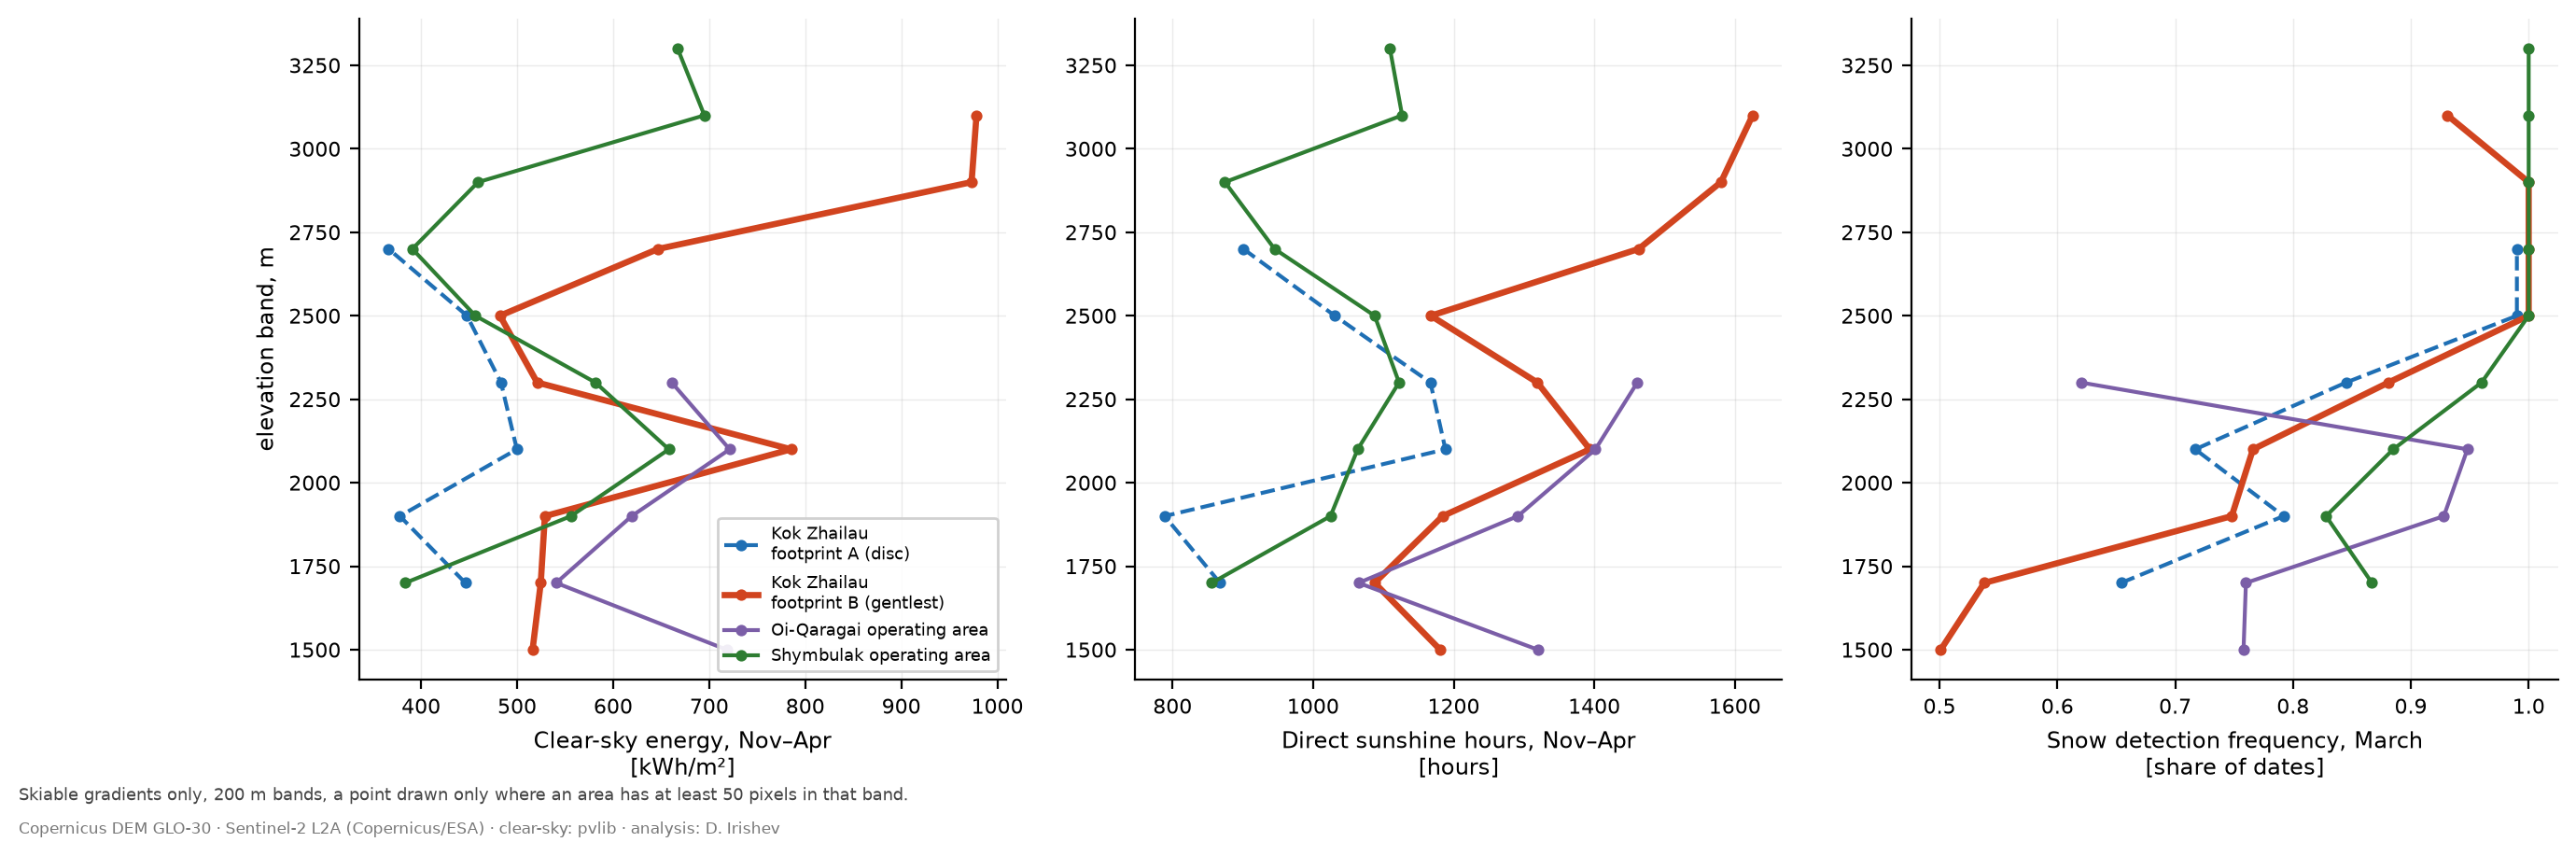

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/kz_project/png/05_three_area_elevation_bands.png')

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15.2, 4.6))
for ax, (lay, lab, unit) in zip(axes, [
        ("insolation_kwh_m2", "Clear-sky energy, Nov–Apr", "kWh/m²"),
        ("sun_hours", "Direct sunshine hours, Nov–Apr", "hours"),
        ("snow_freq_march", "Snow detection frequency, March", "share of dates")]):
    for name, d in bands.groupby("area"):
        d = d.sort_values("band_low_m")
        style = dict(marker="o", ms=3.4, lw=1.5)
        if name.startswith("Kok Zhailau — footprint B"):
            style.update(color="#d1441f", lw=2.4)
        elif name.startswith("Kok Zhailau"):
            style.update(color="#1f6fb4", ls="--")
        elif name.startswith("Shymbulak"):
            style.update(color="#2e7d32")
        else:
            style.update(color="#7b5ea7")
        ax.plot(d[lay], d.band_low_m + 100, label=name.replace(" — ", "\n"), **style)
    ax.set_xlabel(f"{lab}\n[{unit}]", fontsize=8.5)
    ax.grid(alpha=0.25, lw=0.5)
    ax.tick_params(labelsize=8)
axes[0].set_ylabel("elevation band, m", fontsize=8.5)
axes[0].legend(fontsize=6.4, loc="lower right", framealpha=0.9)
save(fig, "05_three_area_elevation_bands.png",
     "Skiable gradients only, 200 m bands, a point drawn only where an area has "
     "at least 50 pixels in that band.")

## 6. Engineering check: does the DEM choice change the answer?

Three global DEMs agree on elevation to a few metres, and a table of elevation
differences is the half of a DEM check that flatters every product. The
planning does not read elevation — it reads slope, horizon, insolation and
sunshine hours. So the **whole chain** is re-run on NASADEM (SRTM, 2000) and
ALOS World 3D-30m, and the products are compared, on skiable gradients only.

In [16]:
import dem_validation as DV
from insolation import accumulate_insolation
from sunhours import sunshine_hours

alt_terrain = {k: DV.terrain_from(k, DEM_GRID) for k in DV.COLLECTIONS}
lonc, latc = DEM_GRID.lonlat_centers()
clat, clon = float(np.mean(latc)), float(np.mean(lonc))
PCACHE = INTERIM / "dem_validation"
PCACHE.mkdir(parents=True, exist_ok=True)


def dem_products(name, tt):
    p = PCACHE / f"products_{name.replace(' ', '_')}.npz"
    if p.exists():
        z = np.load(p)
        return {k: z[k] for k in z.files}
    i1 = accumulate_insolation(f"{OUTLOOK_YEAR}-11-01", f"{OUTLOOK_YEAR+1}-04-30",
                               tt["dem"], tt["slope"], tt["aspect"], tt["svf"],
                               tt["azimuths"], tt["horizon"], clat, clon, verbose=False)
    i2 = accumulate_insolation(f"{OUTLOOK_YEAR}-12-01", f"{OUTLOOK_YEAR}-12-31",
                               tt["dem"], tt["slope"], tt["aspect"], tt["svf"],
                               tt["azimuths"], tt["horizon"], clat, clon, verbose=False)
    h = sunshine_hours(f"{OUTLOOK_YEAR}-11-01", f"{OUTLOOK_YEAR+1}-04-30", tt,
                       clat, clon, by_month=False)
    out = {"ins_nov_apr": i1["total"], "ins_dec": i2["total"], "hours": h["hours"]}
    np.savez_compressed(p, **out)
    return out


prod = {"Copernicus GLO-30": dem_products("Copernicus GLO-30", t)}
for k, v in alt_terrain.items():
    prod[k] = dem_products(k, v)
others_t = {k: v for k, v in alt_terrain.items()}
ref_prod = prod["Copernicus GLO-30"]
others_p = {k: v for k, v in prod.items() if k != "Copernicus GLO-30"}
ski = np.isfinite(t["slope"]) & (t["slope"] >= SKIABLE_SLOPE_MIN) & (t["slope"] <= SKIABLE_SLOPE_MAX)
print(f"comparison mask: {int(ski.sum()):,} skiable pixels "
      f"({ski.sum()*ha:,.0f} ha of the {DEM_GRID.area_km2*100:,.0f} ha window)")

inputs = pd.concat([
    DV.compare_layer(t["dem"], {k: v["dem"] for k, v in others_t.items()}, "elevation_m", ski),
    DV.compare_layer(t["slope"], {k: v["slope"] for k, v in others_t.items()}, "slope_deg", ski),
    DV.compare_layer(t["svf"], {k: v["svf"] for k, v in others_t.items()}, "sky_view_factor", ski),
], ignore_index=True)
products = pd.concat([
    DV.compare_layer(ref_prod["ins_nov_apr"], {k: v["ins_nov_apr"] for k, v in others_p.items()},
                     "insolation_nov_apr_kwh_m2", ski, relative=True),
    DV.compare_layer(ref_prod["ins_dec"], {k: v["ins_dec"] for k, v in others_p.items()},
                     "insolation_december_kwh_m2", ski, relative=True),
    DV.compare_layer(ref_prod["hours"], {k: v["hours"] for k, v in others_p.items()},
                     "direct_sun_hours_nov_apr", ski, relative=True),
], ignore_index=True)
dem_chain = pd.concat([inputs, products], ignore_index=True)
dem_chain.to_csv(OUT_TAB / "dem_propagation.csv", index=False)
print()
print(dem_chain[["layer", "dem", "diff_median", "diff_std", "diff_p95_abs",
                 "pct_p95_abs", "correlation"]].to_string(index=False))

comparison mask: 32,167 skiable pixels (2,895 ha of the 4,215 ha window)

                     layer         dem  diff_median  diff_std  diff_p95_abs  pct_p95_abs  correlation
               elevation_m     NASADEM        0.633     6.379        13.165          NaN     0.999890
               elevation_m ALOS AW3D30        2.480     5.818        14.401          NaN     0.999911
                 slope_deg     NASADEM       -1.436     3.426         7.464          NaN     0.836281
                 slope_deg ALOS AW3D30        0.314     3.148         6.843          NaN     0.866975
           sky_view_factor     NASADEM        0.011     0.019         0.047          NaN     0.902376
           sky_view_factor ALOS AW3D30       -0.002     0.017         0.039          NaN     0.932495
 insolation_nov_apr_kwh_m2     NASADEM        2.493    56.636       116.231       23.268     0.981026
 insolation_nov_apr_kwh_m2 ALOS AW3D30       -1.759    45.073        93.362       21.106     0.988088
insolati

In [17]:
ranks = []
for key, lab in [("ins_nov_apr", "insolation_nov_apr_kwh_m2"),
                 ("ins_dec", "insolation_december_kwh_m2"),
                 ("hours", "direct_sun_hours_nov_apr")]:
    for k, v in others_p.items():
        r = DV.rank_shift(ref_prod[key], v[key], ski)
        if r:
            ranks.append({"layer": lab, "dem": k, **r})
rank_tbl = pd.DataFrame(ranks)
rank_tbl.to_csv(OUT_TAB / "dem_rank_stability.csv", index=False)
print(rank_tbl[["layer", "dem", "top_n", "overlap", "overlap_share",
                "spearman_rho"]].to_string(index=False))

e_r = dem_chain[(dem_chain.layer == "elevation_m")].correlation.min()
s_r = dem_chain[(dem_chain.layer == "slope_deg")].correlation.min()
dec = dem_chain[dem_chain.layer == "insolation_december_kwh_m2"]
print(f"""
The result an employer should take from this section:

  elevation agrees at r = {e_r:.4f}; slope, built from the same pixels, at r = {s_r:.3f}.
  Agreement does not survive differentiation, and differentiation is where the
  planning lives.

  Bias is negligible — December median difference {dec.diff_median.abs().max():.1f} kWh/m² at worst — but
  the spread is not: at the 95th percentile the December figure moves by
  {dec.pct_p95_abs.min():.0f}-{dec.pct_p95_abs.max():.0f} % of its own value depending on which open DEM you used.

  What does survive is the ranking: {100*rank_tbl.overlap_share.min():.0f}-{100*rank_tbl.overlap_share.max():.0f} % of the top tenth of terrain is
  the same ground whichever DEM is chosen, at Spearman {rank_tbl.spearman_rho.min():.3f}-{rank_tbl.spearman_rho.max():.3f}.

So: screen sites with this, on any of the three. Do not sign off a single
site's December number on it without measurement.""")

                     layer         dem  top_n  overlap  overlap_share  spearman_rho
 insolation_nov_apr_kwh_m2     NASADEM   3217     2727         0.8477      0.971851
 insolation_nov_apr_kwh_m2 ALOS AW3D30   3217     3042         0.9456      0.977303
insolation_december_kwh_m2     NASADEM   3217     2761         0.8583      0.955245
insolation_december_kwh_m2 ALOS AW3D30   3217     3042         0.9456      0.963368
  direct_sun_hours_nov_apr     NASADEM   3217     2846         0.8847      0.966285
  direct_sun_hours_nov_apr ALOS AW3D30   3217     3003         0.9335      0.975538

The result an employer should take from this section:

  elevation agrees at r = 0.9999; slope, built from the same pixels, at r = 0.836.
  Agreement does not survive differentiation, and differentiation is where the
  planning lives.

  Bias is negligible — December median difference 0.3 kWh/m² at worst — but
  the spread is not: at the 95th percentile the December figure moves by
  50-66 % of its own value

## 7. Weather data: what reanalysis can carry, and where it stops

A December opening is a weather commitment, so the weather inputs deserve the
same treatment as the DEM. Two things matter here and neither is a detail:

* **Reanalysis resolution against this relief.** ERA5-Land is ~9 km and ERA5
  ~31 km. The project window is 6 km across and spans 1,867 m of relief. A
  single ERA5 cell flattens the whole mountain, so reanalysis here is a
  *regional season descriptor*, not a site record.
* **ERA5-Land returns no precipitation at this point** through the archive API,
  so snowfall comes from ERA5 instead and is labelled separately rather than
  silently summed to zero — which is what an all-NaN sum would have produced.

In [18]:
import weather
from config import SEASONS

wx = weather.era5_land_daily("2022-11-01", f"{date.today().year}-{date.today().month:02d}-01")
wx_season = weather.season_summary(wx, SEASONS)
wx_season.to_csv(OUT_TAB / "reanalysis_season_summary.csv", index=False)
print(wx_season.to_string(index=False))
print("\nsources:", json.dumps(wx.attrs, indent=1)[:600])

monthly = (wx.assign(month=wx["date"].dt.month)
           .groupby("month")
           .agg(mean_T_C=("temperature_2m_mean", "mean"),
                min_T_C=("temperature_2m_min", "min"),
                days_Tmax_below_0C=("temperature_2m_max", lambda s: int((s < 0).sum())),
                n_days=("temperature_2m_mean", "size"))
           .round(2).reset_index())
monthly = monthly[monthly.month.isin([11, 12, 1, 2, 3, 4])]
monthly.to_csv(OUT_TAB / "reanalysis_monthly_climatology.csv", index=False)
print()
print(monthly.to_string(index=False))

outlooks = json.load(open(Path.cwd().parent / "docs" / "seasonal_outlooks.json"))
print("\npublished seasonal outlooks on file:")
for k, v in outlooks.items():
    print(f"  {k}: {v.get('issuer','')[:60]} | issued {v.get('issued','?')} | "
          f"{v.get('spatial_scale','')[:58]}")

 season  n_days  mean_T_C  days_Tmax_below_0C  snowfall_sum_cm  precip_sum_mm
2022/23     181     -3.88                  94            122.2          391.1
2023/24     182     -3.20                  81            149.4          420.0
2024/25     181     -3.60                  96            107.3          298.8
2025/26     181     -1.89                  68            110.6          343.6

sources: {
 "temperature_dataset": "ERA5-Land daily via Open-Meteo Historical Weather API (~9 km grid)",
 "precipitation_dataset": "ERA5 (~31 km) - ERA5-Land returned no precipitation at this point",
 "precip_model_used": "era5",
 "request_point_lon": 77.00433,
 "request_point_lat": 43.14239,
 "model_grid_elevation_m": 2235.0,
 "timezone": "Asia/Almaty",
 "units": {
  "time": "iso8601",
  "temperature_2m_mean": "\u00b0C",
  "temperature_2m_min": "\u00b0C",
  "temperature_2m_max": "\u00b0C",
  "snowfall_sum": "cm",
  "precipitation_sum": "mm"
 },
 "retrieved": "2026-11-19",
 "caveat": "Both reanalyses a

## 8. What this cannot settle, and what I would measure

Everything above is geometry and detection frequency. Neither is a snowpack,
and no amount of further processing turns one into the other. The table below
is the handover: the quantities a GIS or engineering team would still have to
obtain locally, and why orbit cannot supply them.

In [19]:
needed = pd.DataFrame([
    {"question": "snow depth and water equivalent",
     "needed_measurement": "snow pillow or ultrasonic depth sensor plus manual density "
                           "cores, on at least one shaded and one sunny plot in the "
                           "same elevation band",
     "why_satellite_cannot": "optical imagery sees the surface, not the depth below it"},
    {"question": "real (not clear-sky) irradiance",
     "needed_measurement": "two pyranometers on contrasting aspects inside the footprint",
     "why_satellite_cannot": "the model here is clear-sky by construction; cloud "
                             "attenuation is unmeasured"},
    {"question": "the December sun figure for one specific site",
     "needed_measurement": "a horizon survey from the site, or a short-baseline "
                           "photogrammetric or lidar DEM",
     "why_satellite_cannot": f"the three open DEMs disagree by "
                             f"{dec.pct_p95_abs.min():.0f}-{dec.pct_p95_abs.max():.0f} % at the 95th percentile on "
                             f"exactly this quantity (section 6)"},
    {"question": "snowmaking windows",
     "needed_measurement": "wet-bulb temperature at the gun line, wind speed and "
                           "direction, water yield and temperature, equipment curves",
     "why_satellite_cannot": "none of these quantities is observed from orbit"},
    {"question": "season opening date",
     "needed_measurement": "a continuous depth record against an operating threshold, "
                           "over several seasons",
     "why_satellite_cannot": "a 5-day revisit with cloud gaps cannot resolve a "
                             "threshold crossing to the day"},
    {"question": "avalanche terrain classification",
     "needed_measurement": "snowpack profiles, wind transport and loading patterns, "
                           "mapped start and runout zones, local forecaster judgement",
     "why_satellite_cannot": "slope angle is geometry; release depends on the snowpack"},
    {"question": "mid-winter snow statistics on shaded ground",
     "needed_measurement": "ground observation, or Sentinel-1 SAR wet-snow retrieval "
                           "to see through cloud",
     "why_satellite_cannot": f"in the thinnest month only "
                             f"{100*worst.qualifying_share:.0f} % of this window has four clear "
                             f"observations, and that subset is biased "
                             f"{worst['insolation__skew']:+.0f} kWh/m² sunnier (section 4)"},
    {"question": "where the beginner terrain can physically go",
     "needed_measurement": "a design-grade survey of the gentle benches and of what can "
                           "be linked by lift",
     "why_satellite_cannot": f"a 30 m DEM resolves that the gentle ground arrives in "
                             f"{nB} pieces, not whether two of them can be joined"},
])
needed.to_csv(OUT_TAB / "local_measurements_required.csv", index=False)
for _, r in needed.iterrows():
    print(f"\n{r['question']}\n  need : {r['needed_measurement']}\n  why  : {r['why_satellite_cannot']}")


snow depth and water equivalent
  need : snow pillow or ultrasonic depth sensor plus manual density cores, on at least one shaded and one sunny plot in the same elevation band
  why  : optical imagery sees the surface, not the depth below it

real (not clear-sky) irradiance
  need : two pyranometers on contrasting aspects inside the footprint
  why  : the model here is clear-sky by construction; cloud attenuation is unmeasured

the December sun figure for one specific site
  need : a horizon survey from the site, or a short-baseline photogrammetric or lidar DEM
  why  : the three open DEMs disagree by 50-66 % at the 95th percentile on exactly this quantity (section 6)

snowmaking windows
  need : wet-bulb temperature at the gun line, wind speed and direction, water yield and temperature, equipment curves
  why  : none of these quantities is observed from orbit

season opening date
  need : a continuous depth record against an operating threshold, over several seasons
  why  : a 5-day 

In [20]:
meta = {
    "run_date": RUN_DATE,
    "area": AREA_LABEL,
    "bbox": list(AOI_BBOX_WGS84),
    "window_km2": round(DEM_GRID.area_km2, 2),
    "derivation": AREA_NOTE,
    "published_parameters": {r.parameter: r.published for _, r in published.iterrows()},
    "footprints": {
        "stated_area_ha": PROJECT_AREA_HA,
        "A_pieces": nA, "B_pieces": nB,
        "B_largest_piece_ha": round(bigB * ha, 1),
        "A_green_blue_share": float(gb.loc[gb.area == NAME_A, "green_blue_share"].iloc[0]),
        "B_green_blue_share": float(gb.loc[gb.area == NAME_B, "green_blue_share"].iloc[0]),
    },
    "sun": {"horizon_azimuths": HORIZON_N_AZIMUTH,
            "sunshine_step_min": SUN_HOUR_STEP_MIN,
            "december_hours_median_A": float(dA), "december_hours_median_B": float(dB)},
    "snow": {"scenes": int(len(manifest)), "dates": int(len(days)),
             "failures": int(len(failed)),
             "scene_cache_reused_from": slice_info["source"],
             "reuse_check_differing_pixels": int(check["snow"] + check["valid"]),
             "thinnest_month": int(worst.month),
             "thinnest_month_qualifying_share": float(worst.qualifying_share)},
    "dem_validation": {
        "collections": DV.COLLECTIONS,
        "elevation_min_correlation": float(e_r),
        "slope_min_correlation": float(s_r),
        "top_decile_overlap_min": float(rank_tbl.overlap_share.min()),
        "top_decile_overlap_max": float(rank_tbl.overlap_share.max()),
    },
    "three_area_reference": REF,
}
(OUT_TIF / "project_metadata.json").write_text(json.dumps(meta, indent=1))
print(json.dumps(meta, indent=1)[:1500])
print("\ntables:", sorted(p.name for p in OUT_TAB.glob("*.csv")))
print("figures:", sorted(p.name for p in OUT_PNG.glob("*.png")))

{
 "run_date": "2026-11-19",
 "area": "Kok Zhailau project-scale window",
 "bbox": [
  76.965,
  43.115,
  77.045,
  43.17
 ],
 "window_km2": 42.15,
 "derivation": "Project-scale window centred on the plateau reference point. Kazakh Tourism Development states a project territory of 1,022 ha with about 20 ha built up; no boundary has been published. The 1,022 ha footprints are therefore derived inside this window (see footprint.py) and this window is the surrounding context, not the project area.",
 "published_parameters": {
  "piste length": "60 km",
  "lifts": "17 (11 cableways by POMA; the other 6 are not described)",
  "share of runs green and blue": "about 70 %",
  "designed daily capacity": "up to 10,000 skiers/day",
  "project territory": "1,022 ha",
  "built-up area": "about 20 ha (2.0 % of the territory)",
  "launch": "2028/12",
  "boundary / lift alignments / station coordinates": "not published",
  "lift capacity (persons per hour)": "not published",
  "piste length by diffic